Stroke Prediction Dataset - jaybat1453 - 10/22/2026

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Set style for better-looking plots
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

# Load the dataset
df = pd.read_excel(r"C:\Users\Student\Downloads\Stroke_Prediction_Excel_Analysis_jaybat1453.xlsx", sheet_name='Patient Data')
print(f'Dataset shape: {df.shape}')
print(f'Columns: {list(df.columns)}')
df.head()

Dataset shape: (15000, 34)
Columns: ['Patient ID', 'Patient Name', 'Age', 'Gender', 'Hypertension', 'Heart Disease', 'Marital Status', 'Work Type', 'Residence Type', 'Average Glucose Level', 'Body Mass Index (BMI)', 'Smoking Status', 'Alcohol Intake', 'Physical Activity', 'Stroke History', 'Family History of Stroke', 'Dietary Habits', 'Stress Levels', 'Systolic Blood Pressure', 'Diastolic Blood Pressure', 'HDL Cholesterol', 'LDL Cholesterol', 'Not Reported', 'Blurred Vision', 'Dizziness', 'Seizures', 'Weakness', 'Severe Fatigue', 'Headache', 'Confusion', 'Difficulty Speaking', 'Numbness', 'Loss of Balance', 'Diagnosis']


,Patient ID,Patient Name,Age,Gender,Hypertension,Heart Disease,Marital Status,Work Type,Residence Type,Average Glucose Level,...,Dizziness,Seizures,Weakness,Severe Fatigue,Headache,Confusion,Difficulty Speaking,Numbness,Loss of Balance,Diagnosis
0,18153,Mamooty Khurana,56,Male,0,1,Married,Self-employed,Rural,130.91,...,0,0,0,0,1,0,1,0,0,Stroke
1,62749,Kaira Subramaniam,80,Male,0,0,Single,Self-employed,Urban,183.73,...,1,0,0,0,1,1,0,0,1,Stroke
2,32145,Dhanush Balan,26,Male,1,1,Married,Never Worked,Rural,189.00,...,1,1,0,0,0,0,0,0,0,Stroke
3,6154,Ivana Baral,73,Male,0,0,Married,Never Worked,Urban,185.29,...,0,1,0,1,1,1,0,0,0,No Stroke
4,48973,Darshit Jayaraman,51,Male,1,1,Divorced,Self-employed,Urban,177.34,...,0,0,0,0,0,0,1,0,0,Stroke


In [2]:
# Quick data quality check
print('Missing values:', df.isnull().sum().sum())
print('Duplicate rows:', df.duplicated().sum())
print('\nDiagnosis counts:')
print(df['Diagnosis'].value_counts())
print('\nAge summary:')
print(df['Age'].describe())

Missing values: 0
Duplicate rows: 0

Diagnosis counts:
Diagnosis
No Stroke    7532
Stroke       7468
Name: count, dtype: int64

Age summary:
count    15000.000000
mean        54.035667
std         21.063111
min         18.000000
25%         36.000000
50%         54.000000
75%         72.000000
max         90.000000
Name: Age, dtype: float64


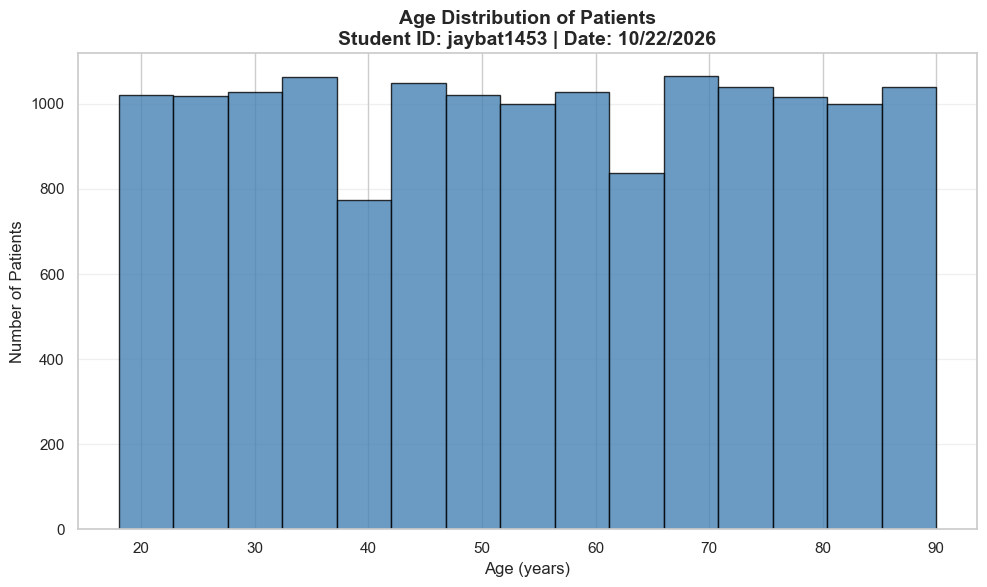

Age group counts (by decade):
Age
18-29    2453
30-39    2062
40-49    2039
50-59    2048
60-69    2105
70-79    2080
80-90    2213
Name: count, dtype: int64


In [3]:
plt.figure(figsize=(10, 6))
plt.hist(df['Age'], bins=15, color='steelblue', edgecolor='black', alpha=0.8)
plt.title('Age Distribution of Patients\nStudent ID: jaybat1453 | Date: 10/22/2026', fontsize=14, fontweight='bold')
plt.xlabel('Age (years)', fontsize=12)
plt.ylabel('Number of Patients', fontsize=12)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('age_histogram_jaybat1453.png', dpi=150, bbox_inches='tight')
plt.show()

print('Age group counts (by decade):')
age_bins = pd.cut(df['Age'], bins=[17, 29, 39, 49, 59, 69, 79, 90], labels=['18-29','30-39','40-49','50-59','60-69','70-79','80-90'])
print(age_bins.value_counts().sort_index())

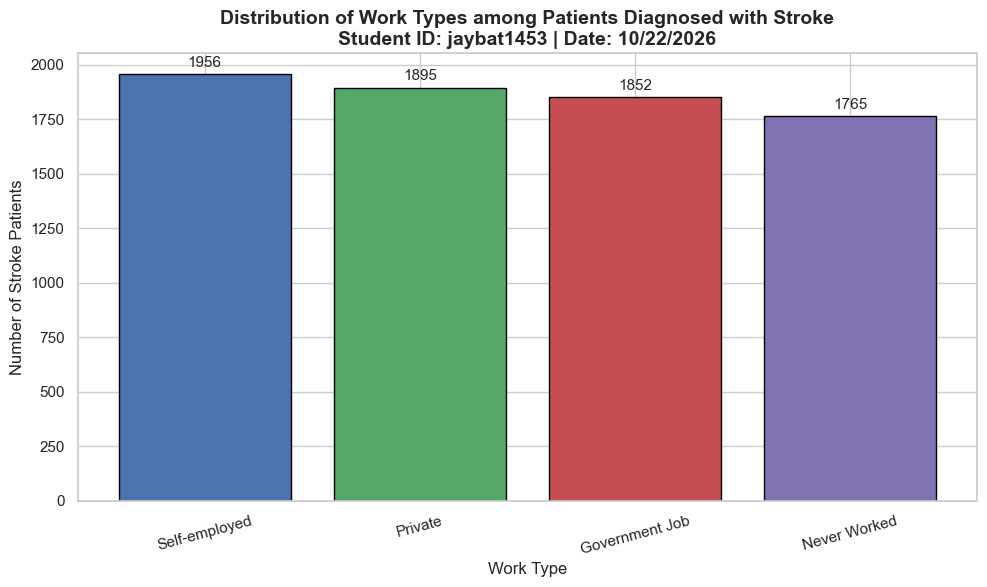

Work Type
Self-employed     1956
Private           1895
Government Job    1852
Never Worked      1765
Name: count, dtype: int64


In [4]:
stroke_df = df[df['Diagnosis'] == 'Stroke']
work_counts = stroke_df['Work Type'].value_counts()

plt.figure(figsize=(10, 6))
bars = plt.bar(work_counts.index, work_counts.values, color=['#4C72B0', '#55A868', '#C44E52', '#8172B2'], edgecolor='black')
plt.title('Distribution of Work Types among Patients Diagnosed with Stroke\nStudent ID: jaybat1453 | Date: 10/22/2026', fontsize=14, fontweight='bold')
plt.xlabel('Work Type', fontsize=12)
plt.ylabel('Number of Stroke Patients', fontsize=12)
plt.xticks(rotation=15)
for bar, count in zip(bars, work_counts.values):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 20, str(count), ha='center', va='bottom', fontsize=11)
plt.tight_layout()
plt.savefig('worktype_bar_jaybat1453.png', dpi=150, bbox_inches='tight')
plt.show()

print(work_counts)

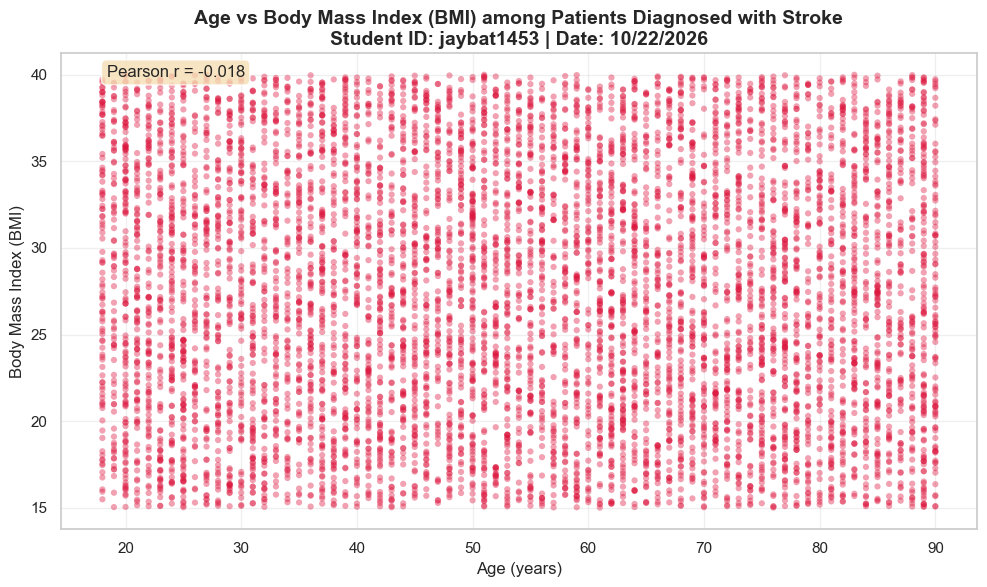

Correlation (Age vs BMI for stroke patients): -0.0185


In [5]:
plt.figure(figsize=(10, 6))
plt.scatter(stroke_df['Age'], stroke_df['Body Mass Index (BMI)'], alpha=0.4, c='crimson', s=20, edgecolors='none')
plt.title('Age vs Body Mass Index (BMI) among Patients Diagnosed with Stroke\nStudent ID: jaybat1453 | Date: 10/22/2026', fontsize=14, fontweight='bold')
plt.xlabel('Age (years)', fontsize=12)
plt.ylabel('Body Mass Index (BMI)', fontsize=12)
plt.grid(True, alpha=0.3)

# Add correlation annotation
corr = stroke_df['Age'].corr(stroke_df['Body Mass Index (BMI)'])
plt.annotate(f'Pearson r = {corr:.3f}', xy=(0.05, 0.95), xycoords='axes fraction',
             fontsize=12, bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))

plt.tight_layout()
plt.savefig('age_bmi_scatter_jaybat1453.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'Correlation (Age vs BMI for stroke patients): {corr:.4f}')

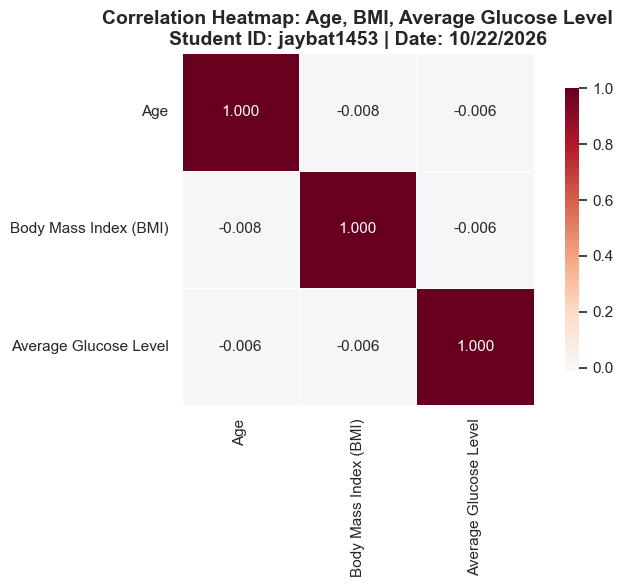

Correlation matrix:
                          Age  Body Mass Index (BMI)  Average Glucose Level
Age                    1.0000                -0.0085                -0.0058
Body Mass Index (BMI) -0.0085                 1.0000                -0.0061
Average Glucose Level -0.0058                -0.0061                 1.0000


In [6]:
num_vars = df[['Age', 'Body Mass Index (BMI)', 'Average Glucose Level']]
corr_matrix = num_vars.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='RdBu_r', center=0, fmt='.3f',
            square=True, linewidths=0.5, cbar_kws={'shrink': 0.8})
plt.title('Correlation Heatmap: Age, BMI, Average Glucose Level\nStudent ID: jaybat1453 | Date: 10/22/2026', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('correlation_heatmap_jaybat1453.png', dpi=150, bbox_inches='tight')
plt.show()

print('Correlation matrix:')
print(corr_matrix.round(4))

In [7]:
# Additional insight: correlation among stroke patients only
stroke_num = stroke_df[['Age', 'Body Mass Index (BMI)', 'Average Glucose Level']]
print('Correlation matrix (Stroke patients only):')
print(stroke_num.corr().round(4))

Correlation matrix (Stroke patients only):
                          Age  Body Mass Index (BMI)  Average Glucose Level
Age                    1.0000                -0.0185                -0.0016
Body Mass Index (BMI) -0.0185                 1.0000                -0.0166
Average Glucose Level -0.0016                -0.0166                 1.0000
